# t-SNE, one iteration at a time

**300 MNIST test images · 30 per digit · seed 42**

Run the cells from top to bottom. The data is loaded from the local `mnist_test.csv.zip` file supplied in this folder; running it needs no internet download. Each image becomes one dot. Its pixels stay fixed while its two map coordinates move.

We will inspect images → compute fixed original affinities **P** → initialise coordinates **Y** → calculate map affinities **Q** → calculate one scalar **KL loss** → differentiate with respect to every coordinate → update all dots together → repeat.

This teaching implementation uses exact pairwise calculations and ordinary gradient descent with backtracking. We deliberately omit early exaggeration, momentum, and approximate neighbours so that every accepted update reduces the same ordinary KL objective. Production t-SNE commonly uses those additional techniques. This run is an explanation of the mechanics, and its layout may differ from library defaults.

**Interactive output:** the last cell contains an iteration slider and image hover viewer. Trust the notebook in Jupyter and run that cell to enable its JavaScript. Static plots also show saved checkpoints.

## 1. Inspect the real images

The file contains the official MNIST test split in CSV form. The first column is the digit label, and the remaining 784 columns are flattened 28 × 28 pixel values. We select 30 test rows from every digit using seed 42, giving 300 images.

Flatten 28 × 28 pixels into 784 features and divide by 255. We keep all 784 features and use Euclidean distances directly, so the relationship to the pixels remains visible.

[7 6 2 2 1 0 8 7 9 4]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
[7001 7576 2765 4456 3543 1651 6311 8931 9705  678]


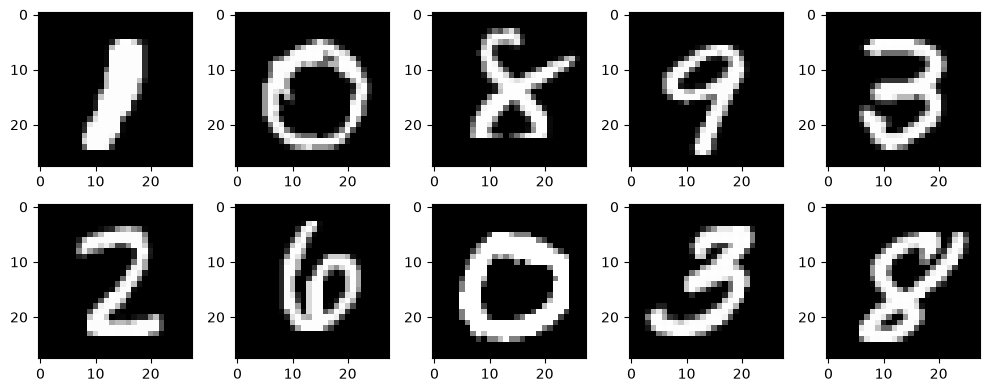

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

DATA_FILE = 'mnist_test.csv'

mnist_rows = pd.read_csv(DATA_FILE, header=None).to_numpy(dtype=np.uint8)

labels_full=mnist_rows[:,0]
pixels_full=mnist_rows[:,1:]


rng=np.random.default_rng(SEED)

def random_sample():
    inspect_list=[]
    inspect_list = rng.choice(
        len(labels_full),
        size=10,
        replace=False,
    )

    labels = labels_full[inspect_list]
    pixels = pixels_full[inspect_list]
    original_ids = inspect_list
    return labels,pixels,original_ids,

labels=random_sample()[0]
print(labels)
pixels=random_sample()[1]
print(pixels)
position = random_sample()[2]
print(position)

images = pixels.reshape(10, 28, 28)


def display_digits(position,images):
    fig, axes = plt.subplots(2,5,figsize=(10,4))

    for position, ax in enumerate(axes.flat):
        ax.imshow(images[position], cmap="grey", vmin=0,vmax=255)
        ax.axis("on")

    plt.tight_layout()
    plt.show()

display_digits(position,images)

Now selecting 300 images to work with.

In [ ]:
def train_data():
    subset_indices = []
    for digit in range(10):
        matching_rows = np.where(labels_full == digit)[0]
        chosen_rows = rng.choice(
            matching_rows,
            size=30,
            replace=False
        )
        subset_indices.extend(chosen_rows) #not an append because that will create a nested list. extend adds each item separately.
    subset_indices = np.asarray(subset_indices)
    rng.shuffle(subset_indices)
    return subset_indices


indices = train_data()
labels = labels_full[indices]
pixels = pixels_full[indices]

X = pixels.astype(np.float64) / 255.0
N = len(X)
assert X.shape == (300, 784)

print(np.bincount(labels, minlength=10))

[30 30 30 30 30 30 30 30 30 30]


## 2. Compare original pixel vectors

`squared_distances[i, j]` is the sum of the squared pixel differences between two images. A low distance means their pixel patterns are similar. We exclude an image itself when inspecting its neighbours.

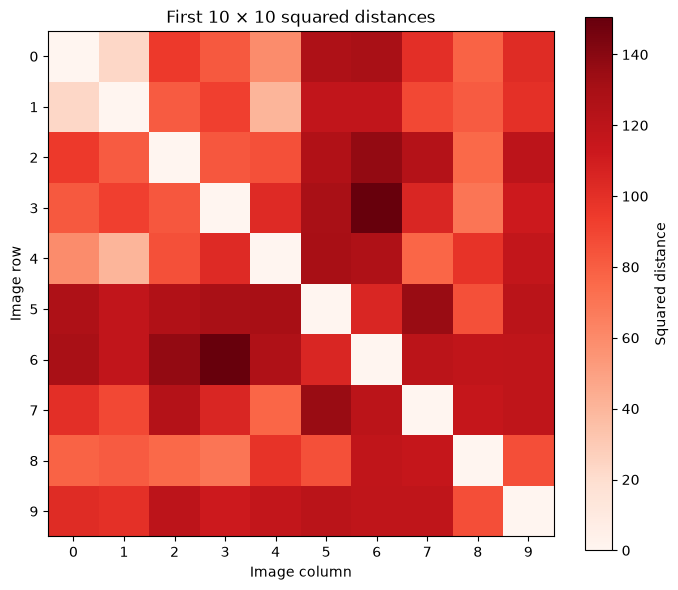

Distance matrix shape: (300, 300)


In [37]:
def pairwise_squared_distances(values):
    """
    Find the squared difference for every pair of 784-pixel images.
    Return a count-by-count matrix of pairwise squared distances.
    """
    count = len(values)
    distances = np.zeros((count, count))

    for i in range(count):
        for j in range(count):
            squared_difference = 0
            for pixel in range(values.shape[1]):
                difference = values[i, pixel] - values[j, pixel]
                squared_difference += difference ** 2
            distances[i, j] = squared_difference

    return distances


squared_distances = pairwise_squared_distances(X)


def show_first_distance_heatmap(distances, size=10):
    """Show the first size-by-size image distances as a heatmap."""
    block = distances[:size, :size]

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(block, cmap="Reds", vmin=0)
    ax.set_xlabel("Image column")
    ax.set_ylabel("Image row")
    ax.set_title(f"First {size} × {size} squared distances")
    fig.colorbar(image, ax=ax, label="Squared distance")

    ax.set_xticks(range(size))
    ax.set_yticks(range(size))

    plt.tight_layout()
    plt.show()


show_first_distance_heatmap(squared_distances)
print("Distance matrix shape:", squared_distances.shape)

## 3. Build P once, before any dots move

For image i, Gaussian weights become conditional probabilities:

$$p_{j|i}=\frac{\exp(-d_{ij}^2/(2\sigma_i^2))}{\sum_{k\ne i}\exp(-d_{ik}^2/(2\sigma_i^2))}.$$

We search for each image's Gaussian width so its conditional distribution has the chosen perplexity. With natural logs, entropy is $H_i=-\sum_j p_{j|i}\log p_{j|i}$ and perplexity is $\exp(H_i)$.

Then symmetrise using $p_{ij}=(p_{j|i}+p_{i|j})/(2N)$. Every conditional row sums to one; the **whole joint P matrix** sums to one. P remains fixed throughout all embedding iterations.

In [38]:
PERPLEXITY = 20.0
ENTROPY_DIFFERENCE_THRESHOLD = 1e-8

def map_affinities_highd(distances, perplexity, entropy_difference_threshold):
    count = len(distances)

    conditional = np.zeros_like(distances)
    sigmas = np.zeros(count)
    achieved = np.zeros(count)

    target_entropy = np.log(perplexity)

    for i in range(count):
        neighbours = np.arange(count) != i
        row = distances[i, neighbours]

        beta = 1.0
        lower_beta = 0.0
        upper_beta = np.inf
        for x in range(100): #100 just max iteration
            weights=np.exp(-beta*(row-row.min())) #remove the minimum to ensure the closest neighbour has weight at 1.
            probabilities = weights/weights.sum() #normalise to find probability of each beta for every pair (related to variance)
            positive = probabilities>0 #only consider those with probability over 0 to remove NaN or -inf values (np.log(0.0) → -inf)
            entropy= -np.sum(probabilities[positive]*np.log(probabilities[positive])) #finding entropy 
            difference = entropy-target_entropy #find how different the entropy is to the given perplexity

            if abs(difference) < entropy_difference_threshold:
                break

            # bisection method
            if difference > 0: #beta is inversely proportional to variance so if entropy is too high (too spread out) increase beta to reduce variance to make gaussian kernal narrower
                lower_beta = beta
                if np.isinf(upper_beta):
                    beta = 2 * beta
                else:
                    beta = (beta + upper_beta) / 2
            else:
                upper_beta = beta
                beta = (lower_beta + beta) / 2

        if abs(difference) >= 1e-6:
            raise RuntimeError(
                f"Perplexity search did not converge for row {i}."
            )

        conditional[i, neighbours] = probabilities
        sigmas[i] = np.sqrt(1.0 / (2.0 * beta))
        achieved[i] = np.exp(entropy)

    P = (conditional + conditional.T) / (2 * count)

    return P, conditional, sigmas, achieved


map_affinities_highd(squared_distances, PERPLEXITY, ENTROPY_DIFFERENCE_THRESHOLD)

(array([[0.00000000e+00, 1.29947628e-04, 8.32198669e-07, ...,
         3.11856252e-07, 1.76237408e-06, 2.16888717e-06],
        [1.29947628e-04, 0.00000000e+00, 3.49904522e-06, ...,
         3.56791896e-07, 2.69659067e-06, 4.62952461e-06],
        [8.32198669e-07, 3.49904522e-06, 0.00000000e+00, ...,
         2.06398980e-06, 4.41338875e-07, 7.82333811e-07],
        ...,
        [3.11856252e-07, 3.56791896e-07, 2.06398980e-06, ...,
         0.00000000e+00, 2.24664529e-04, 2.66090567e-07],
        [1.76237408e-06, 2.69659067e-06, 4.41338875e-07, ...,
         2.24664529e-04, 0.00000000e+00, 1.31161434e-06],
        [2.16888717e-06, 4.62952461e-06, 7.82333811e-07, ...,
         2.66090567e-07, 1.31161434e-06, 0.00000000e+00]], shape=(300, 300)),
 array([[0.00000000e+00, 5.02480241e-02, 8.00403993e-05, ...,
         9.99510376e-05, 4.38850037e-04, 5.07731363e-04],
        [2.77205528e-02, 0.00000000e+00, 1.27560657e-04, ...,
         6.12137614e-05, 3.43678408e-04, 5.59603711e-04],
       

## 4. Put every image at an initial 2D position


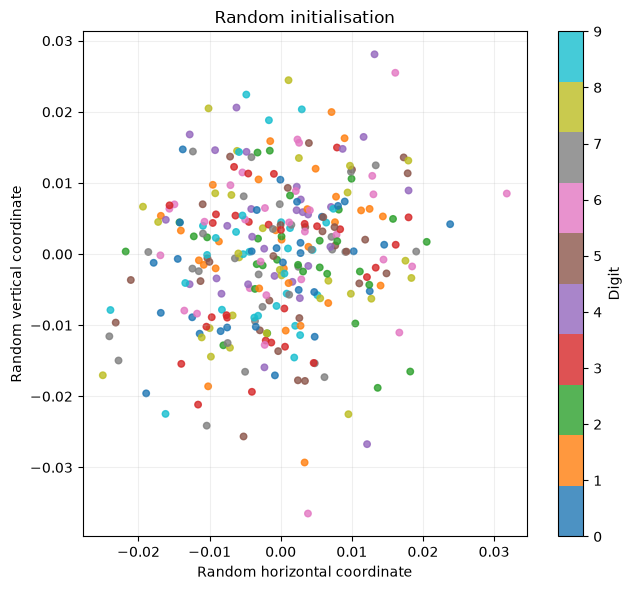

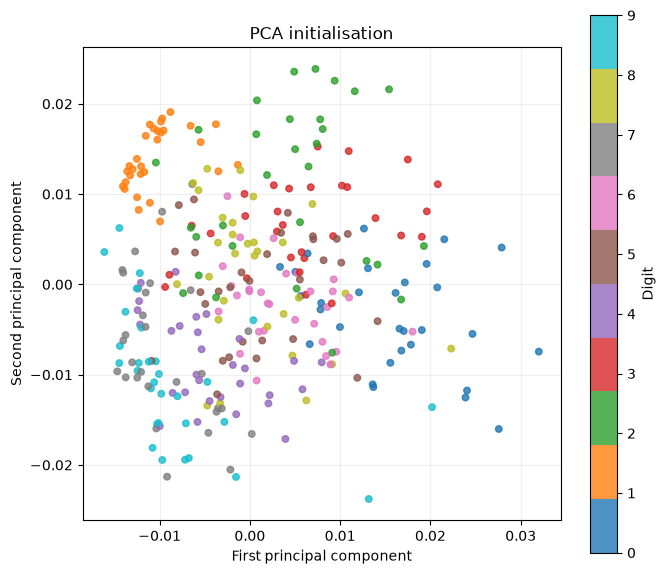

In [39]:
def random_initialise(N):
    '''
    Random initialisation of 2D embedding map
    '''
    Y = rng.normal(0.0, 0.01, size=(N, 2))
    return Y


def pca_initialise(values=None):
    '''
    PCA initialisation of 2D embedding map 
    '''

    centered = values - values.mean(axis=0)
    U, singular_values, components = np.linalg.svd(centered, full_matrices=False)

    Y = centered @ components[:2].T

    # Match the random initialisation scale and remove component magnitude differences.
    Y = Y / Y.std(axis=0, keepdims=True) * 0.01

    #Choose a sign to make largest value direction positive.
    for dimension in range(2):
        largest = np.argmax(np.abs(Y[:, dimension]))
        if Y[largest, dimension] < 0:
            Y[:, dimension] *= -1

    return Y


def plot_random_initialisation(N):
    '''
    Plot the random starting coordinates, coloured by digit label.
    '''
    Y = random_initialise(N)

    fig, ax = plt.subplots(figsize=(7, 6))
    scatter = ax.scatter(Y[:, 0], Y[:, 1], c=labels[:N], cmap="tab10",
                         vmin=0, vmax=9, s=22, alpha=0.8)

    ax.set_xlabel("Random horizontal coordinate")
    ax.set_ylabel("Random vertical coordinate")
    ax.set_title("Random initialisation")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.2)

    fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
    plt.tight_layout()
    plt.show()


def plot_pca_initialisation(values=None):
    '''Plot the PCA starting coordinates, coloured by digit label.'''
    if values is None:
        values = X

    Y = pca_initialise(values)

    fig, ax = plt.subplots(figsize=(7, 6))
    scatter = ax.scatter(Y[:, 0], Y[:, 1], c=labels[:len(Y)], cmap="tab10",
                         vmin=0, vmax=9, s=22, alpha=0.8)

    ax.set_xlabel("First principal component")
    ax.set_ylabel("Second principal component")
    ax.set_title("PCA initialisation")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.2)

    fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
    plt.tight_layout()
    plt.show()


def plot_2d(Y):
    '''
    Plot the 2D coordinates, coloured by digit label.
    '''
    N=len(Y)

    fig, ax = plt.subplots(figsize=(7, 6))
    scatter = ax.scatter(Y[:, 0], Y[:, 1], c=labels[:N], cmap="tab10",
                         vmin=0, vmax=9, s=22, alpha=0.8)

    ax.set_xlabel("Horizontal coordinate")
    ax.set_ylabel("Vertical coordinate")
    ax.set_title("2D embedding")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.2)

    fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
    plt.tight_layout()
    plt.show()

plot_random_initialisation(N)
plot_pca_initialisation(X)

## 5. Turn positions into Q, and calculate one scalar KL loss

$$w_{ij}=\frac{1}{1+\|y_i-y_j\|^2},\quad Z=\sum_{k\ne l}w_{kl},\quad q_{ij}=w_{ij}/Z.$$

$$L=\sum_{i\ne j}p_{ij}\log(p_{ij}/q_{ij}).$$

Both directions of each pair are included. Self-pairs are excluded. An individual term can be negative; the total KL is nonnegative. Moving one dot changes Z and therefore changes every normalised q, even for pairs whose endpoints stayed still.

In [40]:
def map_affinities_2d(Y):
    '''
    Convert 2D coordinates into normalized pair affinities Q
    and unnormalized Student-t weights.
    '''
    differences = Y[:, None, :] - Y[None, :, :] #NxN (300x300) coordinate displacement between dots on 2D
    squared_distances = np.sum(differences ** 2, axis=2)

    weights = 1.0 / (1.0 + squared_distances)
    np.fill_diagonal(weights, 0.0)

    Z = weights.sum()
    Q = weights / Z

    return Q, weights


Y_initial = random_initialise(N)
Q, weights = map_affinities_2d(Y_initial)
print("Q shape:", Q.shape)
print("Q sum:", Q.sum())

Q shape: (300, 300)
Q sum: 1.0


## 6. Differentiate with respect to every coordinate

The KL loss is a function of all $N$ rows of $Y$. For every point $i$, the gradient is

$$
\nabla_{y_i} L=4\sum_{j\ne i}(p_{ij}-q_{ij})w_{ij}(y_i-y_j).
$$

The sign $(P-Q)$ determines attraction or repulsion. If $p_{ij}>q_{ij}$, point $i$ is attracted toward point $j$. If $p_{ij}<q_{ij}$, it is repelled.

In [41]:
def kl_gradient(Y, P):
    '''Calculate the t-SNE KL gradient for all 2D coordinates.'''
    Q, weights = map_affinities_2d(Y)

    differences = Y[:, None, :] - Y[None, :, :] #300x300 coordinate displacement between dots on 2D
    coefficients = 4.0 * (P - Q) * weights  
    gradient = np.sum(coefficients[:, :, None] * differences, axis=1)

    return gradient, Q


P= map_affinities_highd(
    squared_distances,
    PERPLEXITY,
    ENTROPY_DIFFERENCE_THRESHOLD,
)[0]
Y_initial = random_initialise(N)
gradient, Q_initial = kl_gradient(Y_initial, P)

print("Gradient shape:", gradient.shape)
print("Maximum gradient value:", np.max(np.abs(gradient)))

Gradient shape: (300, 2)
Maximum gradient value: 0.00018724386017244252


## 7. Verifying the derivative numerically (Sanity Check)

In [42]:
def check_kl_gradient(Y, P, point=0, coordinate=0, epsilon=1e-5):
    '''
    Compare the analytical and numerical KL gradients for one coordinate.
    '''
    gradient= kl_gradient(Y, P)[0] 
    analytical = gradient[point, coordinate] #first point=0 selects first point as array index, second 0 selects its x coordinate index

    #Numerical step in +- x
    Y_plus = Y.copy()
    Y_minus = Y.copy()
    Y_plus[point, coordinate] += epsilon
    Y_minus[point, coordinate] -= epsilon

    #Analytical step in +- x
    Q_plus = map_affinities_2d(Y_plus)[0]
    Q_minus = map_affinities_2d(Y_minus)[0]


    #Analytical gradient
    mask = P > 0  # Zero entries of P contribute zero to the KL loss
    loss_plus = np.sum(P[mask] * np.log(P[mask] / Q_plus[mask])) #KL loss positive direction
    loss_minus = np.sum(P[mask] * np.log(P[mask] / Q_minus[mask])) #KL loss negative direction

    #Numerical gradient (rise/run)
    numerical = (loss_plus - loss_minus) / (2 * epsilon)

    print("Numerical gradient:", numerical)
    print("Analytical gradient:", analytical)
    np.testing.assert_allclose(numerical, analytical, rtol=1e-4, atol=1e-8)


Y_check = np.random.default_rng(0).normal(size=Y_initial.shape)
check_kl_gradient(Y_check, P)


Numerical gradient: -0.00017337384861093594
Analytical gradient: -0.00017337383247367254


## 8. Take ONE simultaneous update

$$Y_{\mathrm{new}}=Y-\eta\nabla L(Y).$$

All coordinates move using gradients calculated at the old positions. The learning rate $\eta$ sets the size of that update.

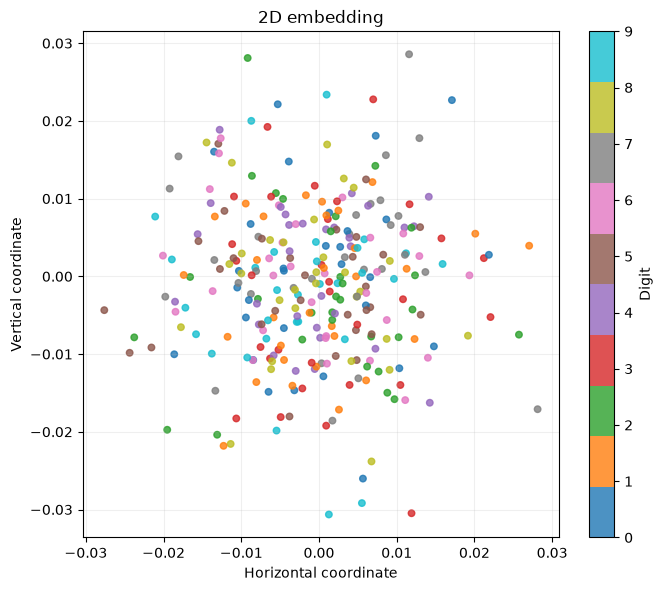

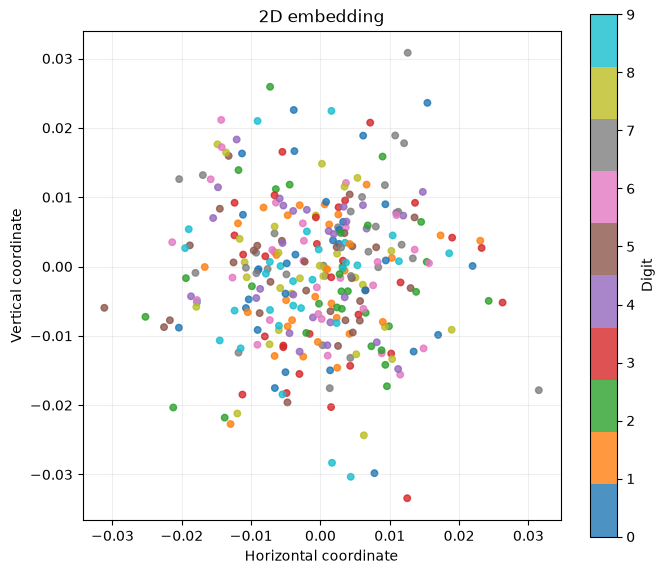

In [43]:
def update_2d(Y, P, nu=25):
    ''' 
    Uses the above formula to update the position of dots
    '''
    gradient = kl_gradient(Y, P)[0] #300x2 gradient matrix
    Y_new = Y - nu * gradient
    return Y_new


Y_new = update_2d(Y_initial, P)
plot_2d(Y_initial)
plot_2d(Y_new)

## 9. Run the iteration loop

Start from the initial coordinates each time. Feed each update into the next iteration and record the KL loss after each update. Use a fixed learning rate of 25 and keep $P$ fixed.

Updates: 1000
Initial KL loss: 2.529168918841081
Final KL loss: 0.8761269055979845


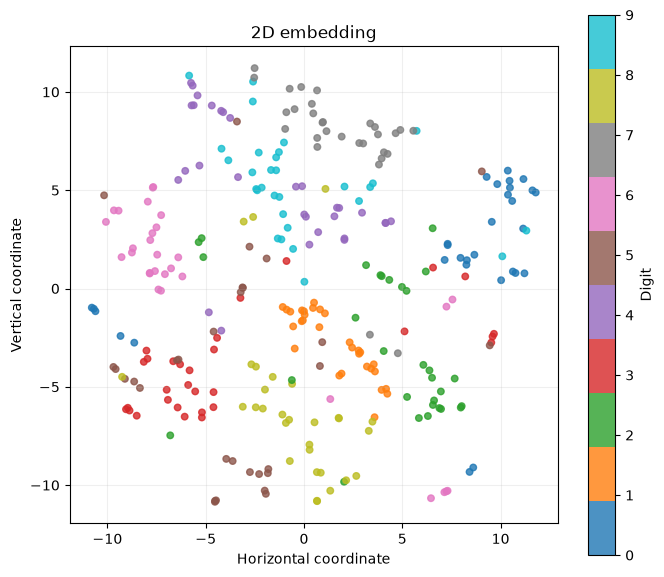

In [44]:
def basic_iteration(Y_initial, P, iterations=1000, nu=25, *, save_positions=False):
    """Return the final embedding, KL history, and optionally the position history."""
    Y = Y_initial.copy()
    positions = [Y.copy()] if save_positions else None
    mask = P > 0
    probabilities = P[mask]
    Q, _ = map_affinities_2d(Y)
    losses = [np.sum(probabilities * np.log(probabilities / Q[mask]))]

    for _ in range(iterations):
        Y = update_2d(Y, P, nu=nu)
        Q, _ = map_affinities_2d(Y)
        loss = np.sum(probabilities * np.log(probabilities / Q[mask]))
        losses.append(loss)
        if save_positions:
            positions.append(Y.copy())

    if save_positions:
        return Y, np.array(losses), np.stack(positions)
    return Y, np.array(losses)


Y_final, kl_history, position_history = basic_iteration(Y_initial, P, save_positions=True)
print("Updates:", len(kl_history) - 1)
print("Initial KL loss:", kl_history[0])
print("Final KL loss:", kl_history[-1])
plot_2d(Y_final)

## 10. Compare positions with arrows

Each arrow starts at an old position (open circle) and points to the updated position (filled dot). The default compares the initial and final positions. To see a single update, set `old_iteration=0` and `new_iteration=1`.

In [ ]:
def overlay_iteration(positions, old_iteration=0, new_iteration=-1):
    """Plot point displacements between two saved iterations."""
    iteration_numbers = range(len(positions))
    old_iteration = iteration_numbers[old_iteration]
    new_iteration = iteration_numbers[new_iteration]
    old = positions[old_iteration]
    new = positions[new_iteration]
    displacement = new - old

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.quiver(old[:, 0], old[:, 1], displacement[:, 0], displacement[:, 1],
              angles="xy", scale_units="xy", scale=1, pivot="tail",
              color="tab:blue", alpha=0.3, width=0.002)
    ax.scatter(old[:, 0], old[:, 1], s=24, facecolors="none",
               edgecolors="0.35", linewidths=0.7, label=f"Iteration {old_iteration}")
    ax.scatter(new[:, 0], new[:, 1], s=14, color="tab:blue",
               label=f"Iteration {new_iteration}")
    ax.set(aspect="equal", xlabel="Horizontal coordinate", ylabel="Vertical coordinate",
           title=f"Point movement from iteration {old_iteration} to {new_iteration}")
    ax.legend()
    return ax


overlay_iteration(position_history)
plt.show()

## 11. Animate the iteration loop

Run this cell after Step 9 to display the animation. It shows the random initial positions, every tenth update, and the final positions. By default the axes rescale as the map spreads out. Read the tick labels to see how the scale changes, or set `autoscale=False` to use fixed axes.

In [ ]:
def animate_iteration(positions, losses, digit_labels, frame_every=10, interval=100, *, autoscale=True):
    """Return an inline animation of the saved positions and KL losses."""
    from pathlib import Path
    from tempfile import TemporaryDirectory

    from IPython.display import Image, Video
    from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter

    if frame_every < 1:
        raise ValueError("frame_every must be at least 1.")
    if interval < 1:
        raise ValueError("interval must be at least 1 millisecond.")

    last_iteration = len(positions) - 1
    frames = list(range(0, last_iteration, frame_every)) + [last_iteration]
    first = positions[0]
    bounds = 1.1 * np.max(np.abs(positions), axis=(1, 2))
    fixed_bound = max(0.01, bounds.max())

    fig, ax = plt.subplots(figsize=(6, 5))
    dots = ax.scatter(first[:, 0], first[:, 1], c=digit_labels,
                      cmap="tab10", vmin=-0.5, vmax=9.5, s=22)
    ax.set(aspect="equal",
           xlabel="Horizontal coordinate", ylabel="Vertical coordinate")
    fig.colorbar(dots, ax=ax, ticks=range(10), label="Digit")
    title = ax.set_title("")

    def draw_frame(iteration):
        bound = max(0.01, bounds[iteration]) if autoscale else fixed_bound
        ax.set(xlim=(-bound, bound), ylim=(-bound, bound))
        dots.set_offsets(positions[iteration])
        title.set_text(f"Iteration {iteration}  |  KL loss {losses[iteration]:.4f}")

    animation = FuncAnimation(fig, draw_frame, frames=frames, interval=interval)
    try:
        with TemporaryDirectory() as directory:
            if FFMpegWriter.isAvailable():
                video_path = Path(directory) / "tsne_iterations.mp4"
                animation.save(video_path, writer=FFMpegWriter(
                    fps=1000 / interval, codec="h264", extra_args=["-pix_fmt", "yuv420p"]
                ))
                return Video(data=video_path.read_bytes(), embed=True, mimetype="video/mp4",
                             html_attributes="controls playsinline")

            gif_path = Path(directory) / "tsne_iterations.gif"
            animation.save(gif_path, writer=PillowWriter(fps=1000 / interval))
            return Image(data=gif_path.read_bytes(), format="gif")
    finally:
        plt.close(fig)


from IPython.display import display

display(animate_iteration(position_history, kl_history, labels[:len(Y_final)]))

## What to try next

1. Change `FOCUS` to inspect a different image and its strongest original neighbours.
2. Change `PERPLEXITY` to 5 or 40 and rerun from the P calculation onward, using the same initial coordinates. P changes, so KL values across these different objectives are not directly comparable as quality scores.
3. Change only the random seed and rerun the coordinate initialisation onward. P stays fixed, so the final KL objectives are comparable.

The direct implementation costs O(N²) time and memory for pairwise operations. Keep the external subset small while learning. Increasing the iteration limit may refine the layout, but small gradients do not guarantee a global optimum or faithful preservation of every neighbourhood.

## Sources

- [van der Maaten & Hinton, Visualizing Data using t-SNE (2008)](https://www.jmlr.org/papers/v9/vandermaaten08a.html). Affinity equations, KL objective, analytical gradient, and production optimisation choices.
- [MNIST test split CSV](https://www.kaggle.com/datasets/oddrationale/mnist-in-csv). The attached `mnist_test.csv.zip` contains 10,000 test rows; this notebook selects a reproducible 300-row subset.
- [Wattenberg et al., How to Use t-SNE Effectively (2016)](https://distill.pub/2016/misread-tsne/). Interpretation of clusters and hyperparameters.